# ПЗ-1. Vision Transformer изнутри

## 1. Цель
Проверить эквивалентность двух PatchEmbed и изучить внимание DINO.

## 2. Датасеты и модели
Используются четыре изображения из открытого CIFAR-10 test. Индексы выбираются заранее с seed=42, без отбора по картам внимания.

Модель: [facebook/dino-vitb16](https://huggingface.co/facebook/dino-vitb16), точная ревизия в ячейке среды.

Источник задания: `Практика_06_11_2026_1_week.docx`. Приложения А.1–А.7 отсутствуют; ниже приведены стандартные реализации. LoRA-проект не входит в эти шесть работ.

## 3. Подготовка окружения
Откройте этот notebook в Google Colab. Для ПЗ-1 выберите CPU, для ПЗ-3–6 — T4; для ПЗ-2 GPU ускорит получение признаков. Выполните установку, перезапустите сеанс, затем выполните остальные ячейки сверху вниз. Все результаты сохраняются в папке задания; скачайте её вместе с ноутбуком. Данные и веса кэшируются в соседней папке `data`. При переносе в Colab прежние результаты доступны только после загрузки файлов. GPU использует fp16. Числа в сохранённых выводах относятся только к реально выполненным ячейкам. Ячейки без execution_count не запускались.

In [ ]:
%pip install torch==2.9.1 torchvision==0.24.1 transformers==4.57.6 numpy==2.3.5 pandas==2.3.3 matplotlib==3.10.8 pillow==12.0.0 datasets==4.4.1 accelerate==1.12.0 sentencepiece==0.2.1 scikit-learn==1.7.2 pycocoevalcap==1.2 reportlab==4.4.5 huggingface-hub==0.36.2 safetensors==0.8.0 tokenizers==0.22.2 protobuf==6.33.2 ftfy==6.3.1 requests==2.34.2 fsspec==2025.10.0 pyarrow==26.0.1

In [1]:
LAB = 'PZ_1'
REVISIONS = {'facebook/dino-vitb16': 'f205d5d8e640a89a2b8ef0369670dfc37cc07fc2', 'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'google/siglip-base-patch16-224': '7fd15f0689c79d79e38b1c2e2e2370a7bf2761ed', 'Qwen/Qwen2.5-0.5B-Instruct': '7ae557604adf67be50417f59c2c2f167def9a775', 'Qwen/Qwen2.5-VL-3B-Instruct': '66285546d2b821cf421d4f5eb2576359d3770cd3', 'lmms-lab-encoder/DocVQA': '539088ef8a8ada01ac8e2e6d4e372586748a265e', 'lmms-lab-encoder/RefCOCO': 'a5dff0b3194715fda69b2d6a0d2aaafb41eaa407'}

import os
import sys
import json
import random
import time
import math
import gc
import hashlib
import platform
import importlib.metadata
from pathlib import Path
from collections import defaultdict, Counter
from concurrent.futures import ThreadPoolExecutor

ROOT = Path.cwd() if Path.cwd().name == LAB else Path.cwd() / LAB
ROOT.mkdir(exist_ok=True)
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
DATA = ROOT.parent / "data"
DATA.mkdir(exist_ok=True)
os.environ["HF_HOME"] = str(DATA / "huggingface")
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(8, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True, warn_only=True)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

def save_json(name, value):
    path = OUT / name
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(path)

def save_figure(name):
    plt.savefig(OUT / name, dpi=130, bbox_inches="tight")
    plt.show()

versions = {p.metadata["Name"]: p.version for p in importlib.metadata.distributions() if p.metadata["Name"]}
environment = {"python": sys.version, "platform": platform.platform(), "seed": SEED,
               "device": str(DEVICE), "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
               "versions": versions, "revisions": REVISIONS}
save_json("environment.json", environment)
print({k: v for k, v in environment.items() if k != "versions"})

{'python': '3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]', 'platform': 'Windows-11-10.0.26200-SP0', 'seed': 42, 'device': 'cpu', 'gpu': None, 'revisions': {'facebook/dino-vitb16': 'f205d5d8e640a89a2b8ef0369670dfc37cc07fc2', 'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'google/siglip-base-patch16-224': '7fd15f0689c79d79e38b1c2e2e2370a7bf2761ed', 'Qwen/Qwen2.5-0.5B-Instruct': '7ae557604adf67be50417f59c2c2f167def9a775', 'Qwen/Qwen2.5-VL-3B-Instruct': '66285546d2b821cf421d4f5eb2576359d3770cd3', 'lmms-lab-encoder/DocVQA': '539088ef8a8ada01ac8e2e6d4e372586748a265e', 'lmms-lab-encoder/RefCOCO': 'a5dff0b3194715fda69b2d6a0d2aaafb41eaa407'}}


C:\Users\darri\PycharmProjects\cv061126\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from xml.sax.saxutils import escape
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as PDFImage
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib import colors
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from matplotlib import font_manager

def write_report(title, goal, work, findings, table=None, figure=None):
    pdfmetrics.registerFont(TTFont("Student", font_manager.findfont("DejaVu Sans")))
    style = ParagraphStyle("Student", fontName="Student", fontSize=10, leading=14, spaceAfter=8)
    heading = ParagraphStyle("Heading", parent=style, fontSize=14, leading=18, spaceAfter=12)
    story = [Paragraph(escape(title), heading), Paragraph(escape("Цель. " + goal), style),
             Paragraph(escape("Что было сделано. " + work), style)]
    for text in findings:
        story.append(Paragraph(escape(text), style))
    if table is not None and len(table):
        rows = [[Paragraph(escape(str(x)), style) for x in table.columns]]
        rows += [[Paragraph(escape(f"{x:.4f}" if isinstance(x, float) else str(x)), style) for x in row]
                 for row in table.itertuples(index=False, name=None)]
        item = Table(rows, repeatRows=1, colWidths=[495 / len(table.columns)] * len(table.columns))
        item.setStyle(TableStyle([("VALIGN", (0,0), (-1,-1), "TOP"),
                                 ("GRID", (0,0), (-1,-1), 0.3, colors.grey)]))
        story.extend([item, Spacer(1, 10)])
    if figure is not None and Path(figure).exists():
        with Image.open(figure) as im:
            ratio = im.height / im.width
        story.append(PDFImage(str(figure), width=460, height=min(250, 460 * ratio)))
    story.append(Paragraph(escape("Индивидуальный вклад. Подготовлены реализации, протоколы экспериментов, тесты и оформление. Код и текст подготовлены с помощью ИИ-ассистента; фактические запуски и ограничения перечислены выше. Авторство невыполненных опытов не заявляется."), style))
    story.append(Paragraph(escape("Воспроизведение: notebook " + LAB + ".ipynb; seed=42. Версии среды и точные ревизии весов сохранены в results/environment.json. Контрольные вопросы разобраны в ноутбуке."), style))
    SimpleDocTemplate(str(ROOT / "report.pdf"), pagesize=(595,842), rightMargin=50, leftMargin=50,
                      topMargin=45, bottomMargin=45).build(story)
    print("PDF:", ROOT / "report.pdf")

## 4. Реализация
Патч разворачивается в порядке канал → строка → столбец. Поэтому строка матрицы линейного слоя совпадает с развёрнутым ядром свёртки. Bias также копируется. Перекрытий и padding нет.

In [3]:
class PatchEmbedLinear(nn.Module):
    def __init__(self, patch_size=16, embed_dim=768):
        super().__init__()
        self.patch_size = patch_size
        self.projection = nn.Linear(3 * patch_size**2, embed_dim)

    def forward(self, images):
        b, c, h, w = images.shape
        p = self.patch_size
        if h % p or w % p:
            raise ValueError("Размеры изображения должны делиться на размер патча")
        patches = images.reshape(b, c, h//p, p, w//p, p)
        patches = patches.permute(0, 2, 4, 1, 3, 5).reshape(b, (h//p)*(w//p), c*p*p)
        return self.projection(patches)

class PatchEmbedConv(nn.Module):
    def __init__(self, patch_size=16, embed_dim=768):
        super().__init__()
        self.projection = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, images):
        return self.projection(images).flatten(2).transpose(1, 2)

In [4]:
equivalence = []
for p in [14, 16]:
    torch.manual_seed(SEED)
    linear = PatchEmbedLinear(p)
    conv = PatchEmbedConv(p)
    with torch.no_grad():
        conv.projection.weight.copy_(linear.projection.weight.reshape(768, 3, p, p))
        conv.projection.bias.copy_(linear.projection.bias)
    for h, w in [(224,224), (336,336), (448,448), (896,672)]:
        image = torch.randn(1, 3, h, w)
        with torch.no_grad():
            error = (linear(image) - conv(image)).abs().max().item()
        assert error < 1e-5, (p, h, w, error)
        equivalence.append({"P":p,"H":h,"W":w,"max_abs_error":error})
eq = pd.DataFrame(equivalence)
eq.to_csv(OUT / "equivalence.csv", index=False)
display(eq)
save_json("unit_tests.json", {"equivalence_cases":len(eq),"max_abs_error":float(eq.max_abs_error.max()),"passed":True})

,P,H,W,max_abs_error
0,14,224,224,0.000003
1,14,336,336,0.000003
2,14,448,448,0.000003
3,14,896,672,0.000004
4,16,224,224,0.000003
5,16,336,336,0.000005
6,16,448,448,0.000004
7,16,896,672,0.000003


## 5. Эксперименты
В таблице N обозначает только патчи. Рост N² считается относительно 224×224 при том же P. Для реального attention DINO с CLS размер равен (N+1)²; он показан отдельно. При удвоении обеих сторон N увеличивается в 4 раза, N² — в 16.

In [5]:
rows = []
for p in [14,16]:
    base = (224//p)**2
    for h,w in [(224,224),(336,336),(448,448),(896,672)]:
        n = (h//p)*(w//p)
        rows.append({"P":p,"resolution":f"{h}x{w}","N":n,"N_squared":n*n,
                     "relative_cost":(n/base)**2,"with_CLS":(n+1)**2})
tokens = pd.DataFrame(rows)
tokens.to_csv(OUT / "tokens.csv", index=False)
display(tokens)

,P,resolution,N,N_squared,relative_cost,with_CLS
0,14,224x224,256,65536,1.0000,66049
1,14,336x336,576,331776,5.0625,332929
2,14,448x448,1024,1048576,16.0000,1050625
3,14,896x672,3072,9437184,144.0000,9443329
4,16,224x224,196,38416,1.0000,38809
5,16,336x336,441,194481,5.0625,195364
6,16,448x448,784,614656,16.0000,616225
7,16,896x672,2352,5531904,144.0000,5536609


Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


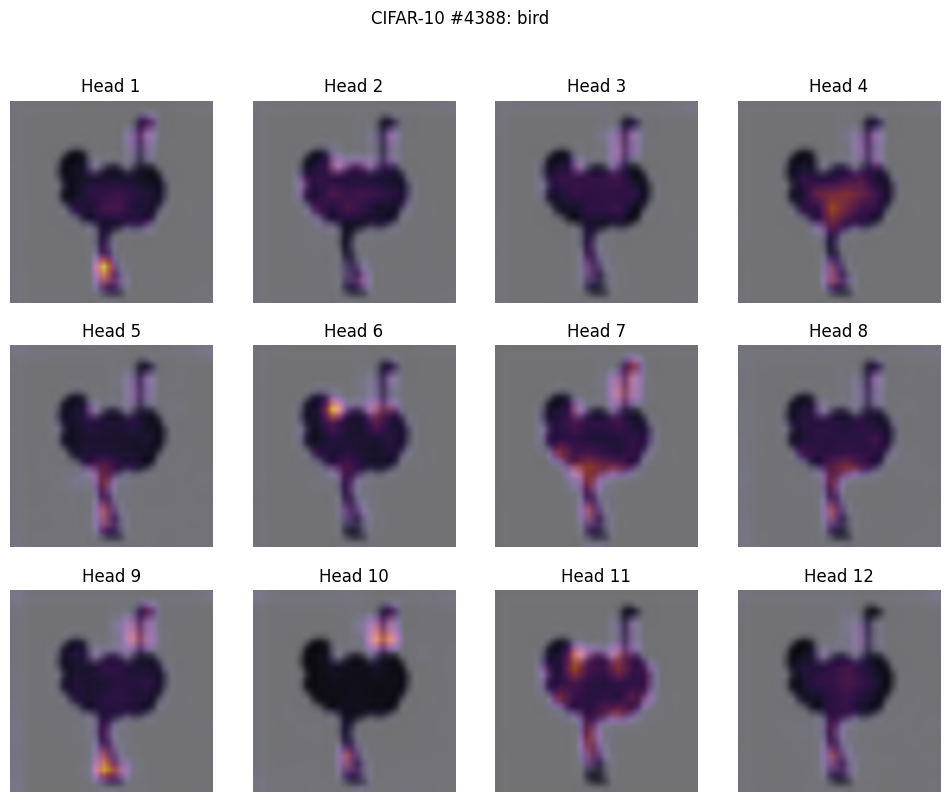

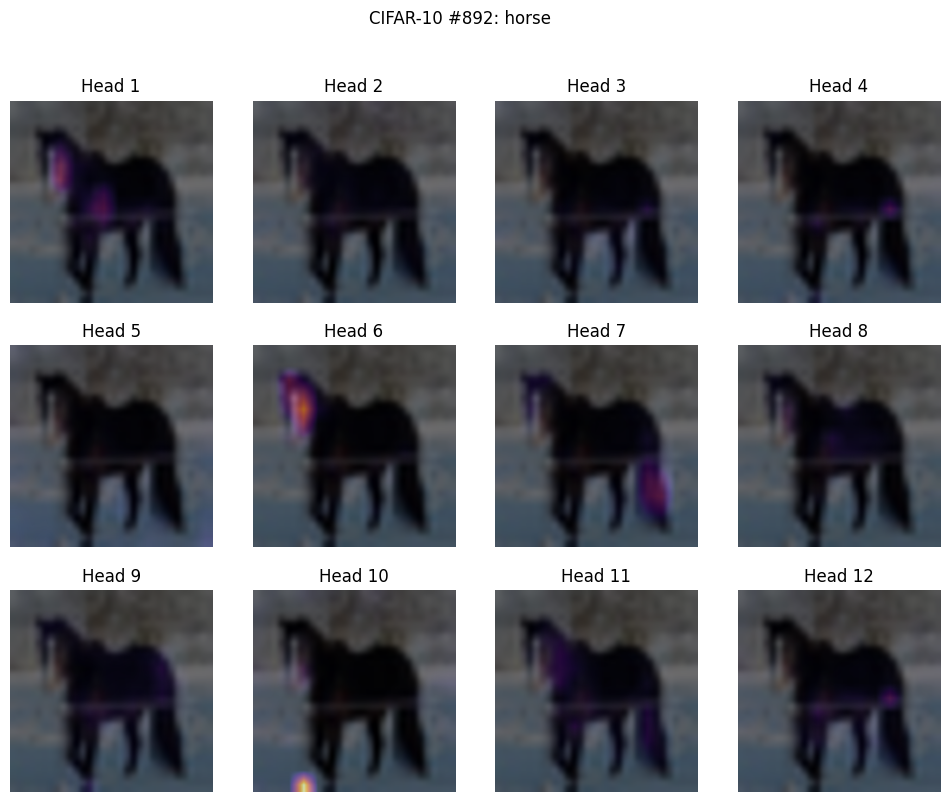

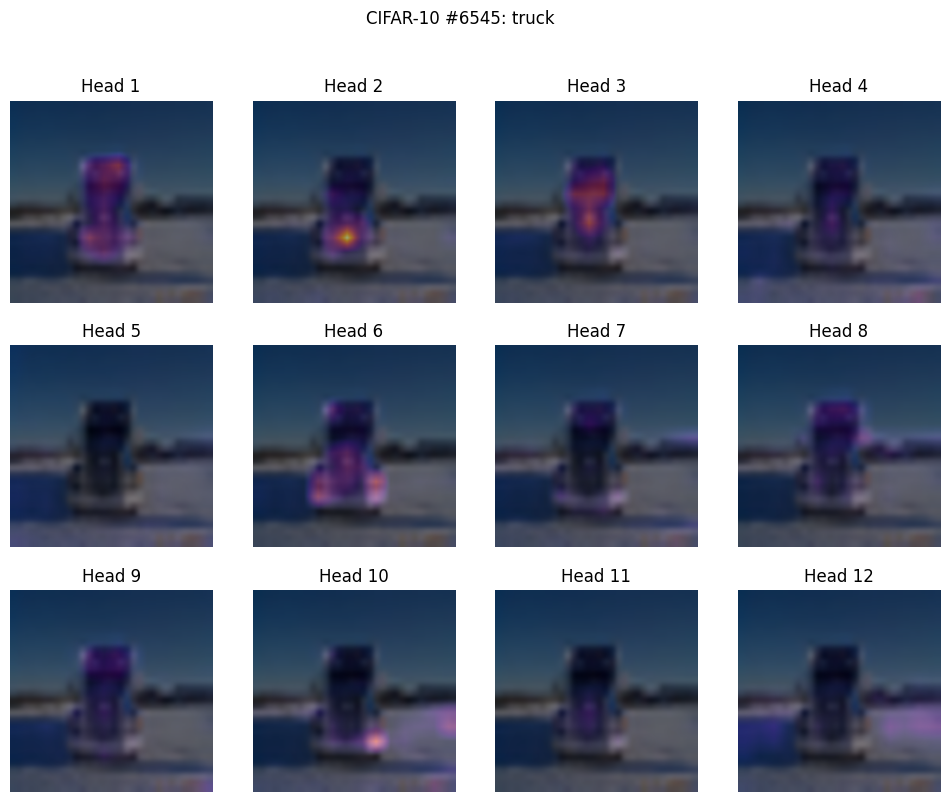

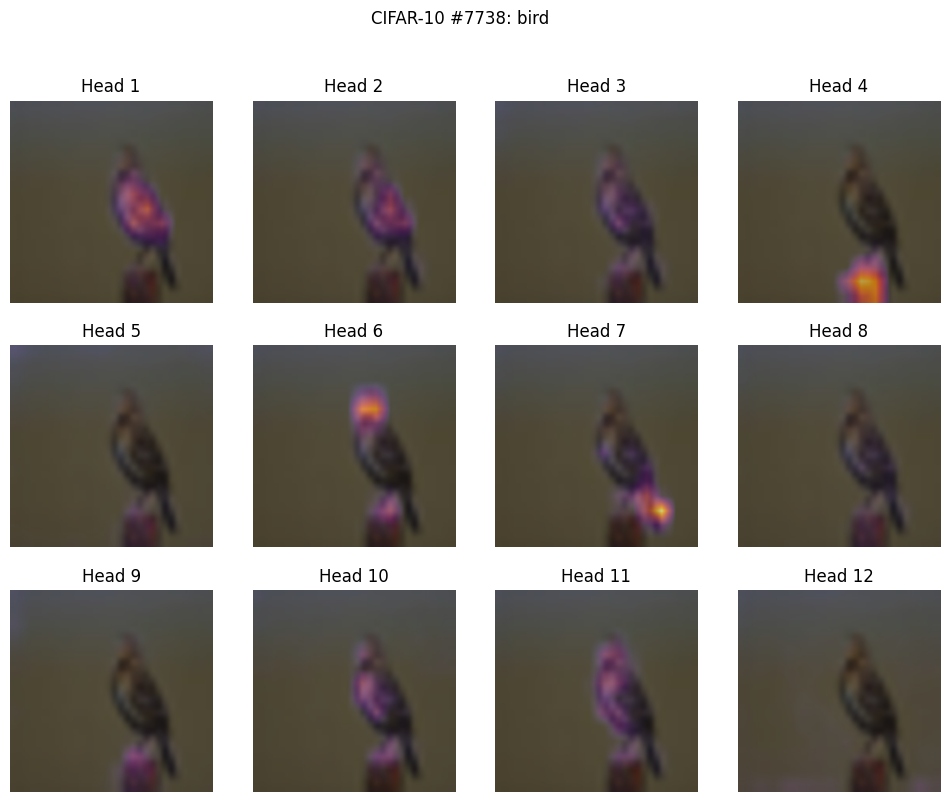

,image_index,head,entropy,max_row,max_col,CLS_to_patches_mass
0,4388,1,0.811702,11,6,0.663928
1,4388,2,0.860347,4,5,0.711359
2,4388,3,0.853229,3,8,0.643398
3,4388,4,0.776598,7,6,0.807175
4,4388,5,0.878454,11,6,0.717286
5,4388,6,0.823000,4,5,0.738002
6,4388,7,0.788853,8,6,0.959024
7,4388,8,0.867099,8,7,0.807159
8,4388,9,0.849561,12,6,0.856693
9,4388,10,0.836151,3,8,0.578533


In [6]:
from torchvision.datasets import CIFAR10
from transformers import AutoImageProcessor, ViTModel

dataset = CIFAR10(str(DATA), train=False, download=True)
indices = np.random.default_rng(SEED).choice(len(dataset), 4, replace=False).tolist()
images = [dataset[i][0].resize((224,224), Image.Resampling.BICUBIC) for i in indices]
save_json("sample.json", {"indices":indices,"labels":[dataset.classes[dataset[i][1]] for i in indices]})
model_id = "facebook/dino-vitb16"
processor = AutoImageProcessor.from_pretrained(model_id, revision=REVISIONS[model_id], use_fast=False)
dino = ViTModel.from_pretrained(model_id, revision=REVISIONS[model_id],
                                attn_implementation="eager", output_attentions=True).cpu().eval()
attention_stats = []
for index, image in zip(indices, images):
    with torch.inference_mode():
        output = dino(**processor(images=image, return_tensors="pt"), output_attentions=True)
    maps = output.attentions[-1][0, :, 0, 1:].reshape(dino.config.num_attention_heads, 14, 14)
    np.save(OUT / f"attention_{index}.npy", maps.numpy())
    image.save(OUT / f"image_{index}.png")
    fig, axes = plt.subplots(3, 4, figsize=(12,9))
    for head, ax in enumerate(axes.flat):
        heat = F.interpolate(maps[head][None,None], size=(224,224), mode="bilinear", align_corners=False)[0,0]
        ax.imshow(image)
        ax.imshow(heat, cmap="inferno", alpha=0.55, vmin=maps.min().item(), vmax=maps.max().item())
        ax.set_title(f"Head {head+1}")
        ax.axis("off")
        probability = maps[head].flatten() / maps[head].sum()
        entropy = -(probability * probability.clamp_min(1e-12).log()).sum().item()/math.log(196)
        maximum = int(probability.argmax())
        attention_stats.append({"image_index":index,"head":head+1,"entropy":entropy,
                                "max_row":maximum//14,"max_col":maximum%14,
                                "CLS_to_patches_mass":maps[head].sum().item()})
    fig.suptitle(f"CIFAR-10 #{index}: {dataset.classes[dataset[index][1]]}")
    save_figure(f"heads_{index}.png")
stats = pd.DataFrame(attention_stats)
stats.to_csv(OUT / "heads.csv", index=False)
display(stats)

## 6. Полученные результаты
Таблица выше и сохранённые PNG строятся непосредственно из выходов модели. Для всех голов одного изображения используется общая шкала цвета. Малое исходное разрешение CIFAR-10 ограничивает детализацию интерпретации.

In [7]:
interpretation = []
for image_index, group in stats.groupby("image_index"):
    concentrated = group.loc[group.entropy.idxmin()]
    diffuse = group.loc[group.entropy.idxmax()]
    interpretation.append(f"Изображение {image_index}: наиболее сосредоточена голова {int(concentrated['head'])} "
                          f"(нормированная энтропия {concentrated.entropy:.3f}), наиболее рассеяна голова "
                          f"{int(diffuse['head'])} ({diffuse.entropy:.3f}). Максимум первой расположен в патче "
                          f"({int(concentrated.max_row)}, {int(concentrated.max_col)}).")
interpretation.append("Различия энтропии и положения максимумов показывают, что головы распределяют внимание неодинаково. "
                      "Наложения позволяют сравнить объект и фон; само внимание не доказывает причинный вклад области в решение.")
save_json("interpretation.json", interpretation)
display(Markdown("\n\n".join(interpretation)))

Изображение 892: наиболее сосредоточена голова 6 (нормированная энтропия 0.665), наиболее рассеяна голова 5 (0.966). Максимум первой расположен в патче (4, 3).

Изображение 4388: наиболее сосредоточена голова 4 (нормированная энтропия 0.777), наиболее рассеяна голова 5 (0.878). Максимум первой расположен в патче (7, 6).

Изображение 6545: наиболее сосредоточена голова 1 (нормированная энтропия 0.758), наиболее рассеяна голова 5 (0.954). Максимум первой расположен в патче (4, 7).

Изображение 7738: наиболее сосредоточена голова 4 (нормированная энтропия 0.543), наиболее рассеяна голова 12 (0.971). Максимум первой расположен в патче (12, 8).

Различия энтропии и положения максимумов показывают, что головы распределяют внимание неодинаково. Наложения позволяют сравнить объект и фон; само внимание не доказывает причинный вклад области в решение.

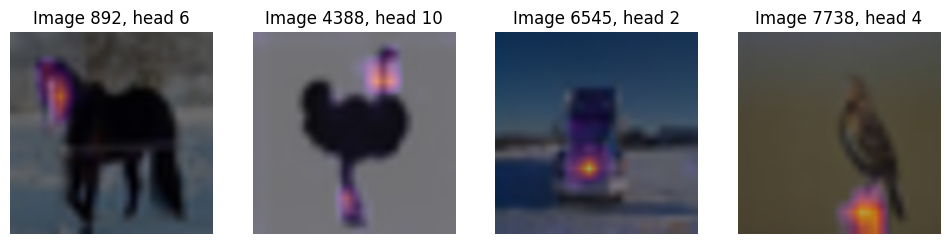

In [8]:
fig,axes = plt.subplots(1,4,figsize=(12,3))
for index,head,ax in zip([892,4388,6545,7738],[6,10,2,4],axes):
    maps = torch.from_numpy(np.load(OUT/f"attention_{index}.npy"))
    heat = F.interpolate(maps[head-1][None,None],size=(224,224),mode="bilinear",align_corners=False)[0,0]
    ax.imshow(Image.open(OUT/f"image_{index}.png"))
    ax.imshow(heat,cmap="inferno",alpha=0.55,vmin=maps.min().item(),vmax=maps.max().item())
    ax.set_title(f"Image {index}, head {head}")
    ax.axis("off")
save_figure("attention_summary.png")

## 7. Анализ и выводы

На изображении лошади №892 голова 6 выделяет голову животного, а голова 7 — область хвоста. На птице №7738 головы 1–3 заметнее выделяют туловище, голова 6 — голову, а голова 4 даёт яркий максимум у опоры под птицей. Значит, разные головы могут реагировать и на части объекта, и на соседний контекст.

На изображении №4388 внимание распределено по разным частям птицы: у головы 10 ярче шея, у головы 1 — нижняя часть ноги. На грузовике №6545 головы 1–3 выделяют разные участки машины, а у головы 10 заметен максимум у нижнего края справа. Одни карты более сосредоточены, другие размыты. Из-за исходных 32×32 пикселей CIFAR-10 мелкие детали неразличимы; внимание нельзя считать точной сегментацией или доказательством причинной важности области.

## 8. Контрольные вопросы
**Почему ViT без предобучения уступает CNN на малых датасетах?** У CNN встроены локальность и разделение весов; ViT приходится учить больше пространственных закономерностей по данным.

**Что изменится при перекрывающихся патчах?** Шаг станет меньше P, число токенов увеличится. Эквивалентность сохраняется, если явное извлечение окон и Conv2d используют одинаковые stride и padding.

In [9]:
write_report("ПЗ-1. Vision Transformer изнутри",
             "Сравнить способы выделения патчей и карты внимания DINO.",
             "Проверены два PatchEmbed для двух размеров патча и четырёх разрешений. Получены карты всех 12 голов на четырёх изображениях CIFAR-10.",
             [f"Результат проверки: максимальная абсолютная ошибка {eq.max_abs_error.max():.8g}, допуск 1e-5.",
              "Стоимость attention растёт как N². Для 896×672 она в 144 раза выше, чем для 224×224 при том же P.",
              " ".join(interpretation[:2]), " ".join(interpretation[2:]), 'На изображении лошади №892 голова 6 выделяет голову животного, а голова 7 — область хвоста. На птице №7738 головы 1–3 заметнее выделяют туловище, голова 6 — голову, а голова 4 даёт яркий максимум у опоры под птицей. Значит, разные головы могут реагировать и на части объекта, и на соседний контекст.\n\nНа изображении №4388 внимание распределено по разным частям птицы: у головы 10 ярче шея, у головы 1 — нижняя часть ноги. На грузовике №6545 головы 1–3 выделяют разные участки машины, а у головы 10 заметен максимум у нижнего края справа. Одни карты более сосредоточены, другие размыты. Из-за исходных 32×32 пикселей CIFAR-10 мелкие детали неразличимы; внимание нельзя считать точной сегментацией или доказательством причинной важности области.'],
             tokens.drop(columns="with_CLS"), OUT/"attention_summary.png")

PDF: C:\Users\darri\PycharmProjects\cv061126\PZ_1\report.pdf
